In [15]:
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin
import matplotlib.pyplot as plt
import time
import pandas as pd
from sklearn.metrics import accuracy_score

**Klasa bazowa _LinBase_ implementujacą metody wspólne klasyfikatorów liniowych.**

In [16]:
class LinBase(BaseEstimator, ClassifierMixin):
    def __init__(self, coef=None, intercept=None, class_labels=None):
        self.coef_ = coef
        self.intercept_ = intercept
        self.class_labels_ = class_labels

    def margin(self, X, y):
        m = y * (X.dot(self.coef_) + self.intercept_)
        return np.min(m), m

    def decision_function(self, X):
        a, b = self.margin(X, np.ones(X.shape[0]))
        return b

    def predict_proba(self, X):
        a, b = self.margin(X, np.ones((X.shape[0],)))
        return np.array([1 - 1 / (1 + np.exp(-b)), 1 / (1 + np.exp(-b))]).T

    def predict(self, X):
        results = np.sign(X.dot(self.coef_) + self.intercept_)
        results_mapped = self.class_labels_[1 * (results > 0)]
        return results_mapped

    def get_params(self, deep=True):
        pass

    def set_params(self, **parameters):
        for parameter, value in parameters.items():
            setattr(self, parameter, value)
        return self

    def __str__(self):
        return "{}[w={}, b={}]".format(self.__class__.__name__, self.coef_, self.intercept_)

**Klasa Preceptorn , dziedzicząca po klasie LinBase i implementująca algorytm uczenia preceptronu zgodnie z regułą perceptronu**

In [17]:
class Perceptron(LinBase):
    def __init__(self, break_time=1, **kwargs):
        super(Perceptron, self).__init__(**kwargs)
        self.break_time_ = break_time

    def fit(self, X, y):
        m, n = X.shape
        self.class_labels_ = np.unique(y)
        if self.coef_ is not None:
            w = self.coef_
        else:
            w = np.zeros(n)

        if self.intercept_ is not None:
            b = self.intercept_
        else:
            b = 0

        i = 0
        k = 0
        t1 = time.time()
        while(k < m):
            if y[i] * (w.dot(X[i, :]) + b) <= 0:
                w = w + X[i, :] * y[i]
                b = b + y[i]
                k = 0
            else:
                k += 1
            i = (i + 1) % m
            t2 = time.time()
            if t2 - t1 > self.break_time_:
                print("Przekroczony czas!")
                break

        self.coef_ = w
        self.intercept_ = b

**Klasa AveragePerceptron (uśrednianie decyzji)**

In [18]:
class AveragePerceptron(LinBase):
    def __init__(self, break_time=10, k_max=1000, **kwargs):
        super(AveragePerceptron, self).__init__(**kwargs)
        self.break_time_ = break_time
        self.v_ = None
        self.v_bias_ = None
        self.k_max = k_max

    def fit(self, X, y):
        m, n = X.shape
        self.class_labels_ = np.unique(y)
        if self.coef_ is not None:
            w = self.coef_
        else:
            w = np.zeros(n)

        if self.intercept_ is not None:
            b = self.intercept_
        else:
            b = 0

        self.v_ = 0 * w
        self.v_bias_ = 0 * b
        i = 0
        k = 0
        c = 0
        t1 = time.time()
        ci = 0
        while(k < self.k_max):
            ci += 1
            if y[i] * (w.dot(X[i, :]) + b) <= 0:
                self.v_ += c * w
                self.v_bias_ += c * b
                w = w + X[i, :] * y[i]
                b = b + y[i]
                k += 1
                c = 1
            else:
                c += 1
            i = (i + 1) % m
            t2 = time.time()
            if t2 - t1 > self.break_time_:
                print("Przekroczony czas!")
                break
        self.v_ += c * w
        self.v_bias_ += c * b
        print(f'Time: {time.time() - t1}\n'
              f'Iterations: {ci}\n'
              f'Number of weight changes: {c}')
        self.coef_ = self.v_
        self.intercept_ = self.v_bias_

**VotedPerceptron (uśrednianie wag)**

In [19]:
class VotedPerceptron(LinBase):
    def __init__(self, break_time=10, k_max=1000, **kwargs):
        super(VotedPerceptron, self).__init__(**kwargs)
        self.break_time_ = break_time
        self.k_max = k_max
        self.c = np.zeros(self.k_max + 1)
        self.v_ = None
        self.v_bias_ = None

    def fit(self, X, y):
        m, n = X.shape
        self.class_labels_ = np.unique(y)
        self.v_ = np.zeros((self.k_max + 1, n))
        self.v_bias_ = np.zeros(self.k_max + 1)
        if self.coef_ is not None:
            w = self.coef_
        else:
            w = np.zeros(n)

        if self.intercept_ is not None:
            b = self.intercept_
        else:
            b = 0

        i = 0
        k = 0
        c = 0
        t1 = time.time()
        ci = 0
        while(k < self.k_max):
            ci += 1
            if y[i] * (w.dot(X[i, :]) + b) <= 0:
                self.v_[k, :] = w
                self.v_bias_[k] = b
                self.c[k] = c
                w = w + X[i, :] * y[i]
                b = b + y[i]
                k += 1
                c = 1
            else:
                c += 1
            i = (i + 1) % m
            t2 = time.time()
            if t2 - t1 > self.break_time_:
                print("Przekroczony czas!")
                break

        self.v_[k, :] = w
        self.v_bias_[k] = b
        self.c[k] = c
        print(f'Time: {time.time() - t1}\n'
              f'Iterations: {ci}\n'
              f'Number of weight changes: {c}')
        self.coef_ = self.v_
        self.intercept_ = self.v_bias_

    def predict(self, X):
        v = np.hstack((self.v_, np.array([self.v_bias_])))
        X = np.vstack((X, np.ones((X.shape[0], 1))))
        return np.sign(np.dot(np.sign(np.dot(v, X)), self.c)).T

    def predict_proba(self, X):
        v = np.hstack((self.v_, np.array([self.v_bias_]).T))
        X = np.hstack((X, np.ones((X.shape[0], 1))))
        a = np.sign(np.dot(np.sign(np.dot(v, X.T)).T, self.c))
        b = 1-a
        return np.vstack((a, b)).T

    def margin(self, X, y):
        return 0, 0

In [20]:
def plot_class(X, y, clf=None, marker=['ro', 'k+'], n=50):
    u_y = np.unique(y)
    for i, u in enumerate(u_y):
        plt.plot(X[y == u, 0], X[y == u, 1], marker[i], label=str(u))

    if clf is not None:
        X1, X2 = np.meshgrid(np.linspace(np.min(X[:, 0]), np.max(X[:, 0]), n),
                             np.linspace(np.min(X[:, 1]), np.max(X[:, 1]), n))
        xx = np.array([X1.ravel(), X2.ravel()]).T
        yy = clf.predict_proba(xx)[:, 1]
        # yy = clf.predict(xx)
        yy = np.reshape(yy, X1.shape)
        plt.contour(X1, X2, yy, [0.5])
    else:
        pass

# Testowanie

**Losowe dane**

[16.09140655 15.99963534] -16
Wartość marginesu wynosi:  0.00028032761088780944


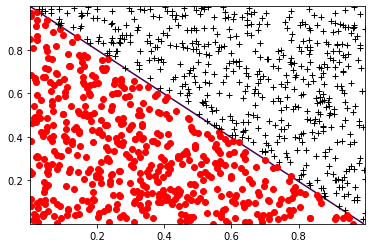

In [21]:
m, n = 1000, 2
X = np.random.rand(m, n)
y = (X.dot([1, 1]) > 1) * 2 - 1
for i, clf in enumerate([Perceptron()]):
    clf.fit(X, y)
    plot_class(X, y, clf)
    print(clf.coef_, clf.intercept_)
    a,b = clf.margin(X, y)
    print('Wartość marginesu wynosi: ', a)

**Wczytanie danych Sonar**

In [23]:
sonar = pd.read_csv("sonar.csv")
X = np.array(sonar.iloc[:,0:-1])
y = np.array(sonar.iloc[:,-1])
y[y == 'Rock'] = -1
y[y == 'Mine'] = 1
print('Real y:')
print(y)

Real y:
[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [26]:
for i, clf in enumerate([Perceptron()]):
    clf.fit(X, y)
    y_pred = clf.predict(X)
    print('Predicted y')
    print(y_pred)
    print('Dokładność klasyfikatora wynosi: ', accuracy_score(list(y), list(y_pred)))

    print(clf.coef_, clf.intercept_)
    a,b = clf.margin(X, y)

Przekroczony czas!
Predicted y
[-1 1 1 1 1 1 1 1 1 1 -1 1 -1 -1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 -1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 -1 1 1 1 1 1 1 -1 -1 -1 -1 1 1 1 -1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 -1 -1 1 1 -1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Dokładność klasyfikatora wynosi:  0.6038647342995169
[ 98.738   45.0144 -26.8517 110.7226   9.4746 -50.1299  18.8357 -63.1653
 -25.0425 -34.3835  27.9031  45.9451 -19.3037 -16.4307  43.4505 -11.0224
 -18.317   72.2195 -30.3693 -14.673   35.5966  25.371  -49.3435  51.2759
 -15.6649  -0.2485  -3.0439  12.97   -32.9614  49.8756 -27.6431 -31.2397
  67.4932 -36.9477  35.6224  -1.9206 -20.4255 -17.7215   9.0206   1.3807
  -4.9803   5.8002   1.1752  38.1194 -24.0088  54.0501 -73.9619  84.6452
  86.6743 -18.5791  30.0665  16.3628  26.38